$ \textbf{Aluna:}$ Alessandra da Silva Dias Malizia   
$ \textbf{Professor:}$ Cristiano Fernandes   
$ \textbf{Data:}$ 9 de Outubro de 2026

$ \textbf{Tese de Mestrado - 2026.1:}$ Modelagem de vazão de rios utilizando a distribuição de Harvey

In [1]:
import numpy as np
import pandas as pd
import datetime as dt
import harvey_gev as harvey

import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from scipy.stats import genextreme, uniform
import seaborn as sns
import statsmodels.api as sm
import importlib
from scipy.special import expit, gamma as gamma_func
# from scipy.constants import EulerGamma

In [2]:
gamma_E = 0.5772156649015329

In [75]:
import inspect
print(inspect.getsource(harvey.fit))

def fit(y, dummy, init_params, method="L-BFGS-B", bounds=None, xi_mode="seasonal"):
    y = np.asarray(y, dtype=float)
    
    idx_alpha = 5
    if xi_mode == "seasonal":
        idx_alpha = 6
        xi_cheia_init = init_params[5]

    mu0_init, varphi_init, phi_init, kappa_init, xi_seca_init = init_params[:5] 
    alpha_init = np.asarray(init_params[idx_alpha:idx_alpha+6], dtype=float)
    beta_init = np.asarray(init_params[idx_alpha+6:], dtype=float)

    x0 = [mu0_init, varphi_init, phi_init, kappa_init, xi_seca_init]
    default_bounds = [
        (None, None),  # mu0
        (1e-8, None),  # varphi > 0
        (-0.999, 0.999),  # -1 < phi < 1
        (1e-8, None),  # kappa > 0
        (1e-8, 0.5)   # xi_seca
    ]  
    
    if xi_mode == "seasonal":
        default_bounds.append((1e-8, 0.5))    # xi_cheia
        x0.append(xi_cheia_init)
                
    x0 += [*alpha_init, *beta_init]    
    x0 = np.array(x0, dtype=float)    
    default_bounds.extend([(None, None)] * 11)

# Dados BR

- Dados BR: Vazão do Rio Amazonas na estação 14990000 [https://www.snirh.gov.br/hidroweb/serieshistoricas]
- Dados Harvey: daily river Exe flow e level na base de Thorverton [https://environment.data.gov.uk/hydrology/station/3c4d4f78-2d0e-474a-b884-65a9daca18fb]  
  Grid Reference: SS9360201602
  River Name: River Exe  
  Catchment Area: 600.9 km²  
  Station Reference (Telemetry): 45118  
  Station ID (WISKI): SS90F011  
  API: https://environment.data.gov.uk/hydrology/doc/reference

In [79]:
path = r"C:\Users\aless\Documents\Mestrado\PUC\Tese\Dados\14990000_Cotas.csv"
data = pd.read_csv(path, skiprows=15, encoding='latin-1', sep=';') #, decimal=','

data = data[['Data', 'Maxima','Minima','Media']]
data['Data'] = pd.to_datetime(data['Data'], format='%d/%m/%Y')
data = data.set_index('Data').dropna(how='all')

data = data.resample('ME').mean()
data.at['2014-08-31','Media'] = 2546
data.at['2014-08-31','Maxima'] = 2906

series = data[['Maxima']].dropna()

print(data.shape)
data.head(3)

(1347, 3)


,Maxima,Minima,Media
Data,,,
1902-09-30,2219.0,NaN,NaN
1902-10-31,1970.0,1777.0,1818.0
1902-11-30,1776.5,1680.5,1716.5


In [4]:
# metadados
pd.set_option('display.max_colwidth', None)
pd.DataFrame(index=['Metadados'], data={
    'Fonte':'''Base de dados de vazão do Rio Amazonas da Agência Nacional de Águas (ANA)''', 
    'Unidade':'centímetros (cm)',
    'Período da série': '{} a {}'.format(series.index.min().strftime('%d/%m/%Y'), series.index.max().strftime('%d/%m/%Y')),
    'Observações': '{} meses'.format(series.shape[0])
}).T

,Metadados
Fonte,Base de dados de vazão do Rio Amazonas da Agência Nacional de Águas (ANA)
Unidade,centímetros (cm)
Período da série,30/09/1902 a 30/11/2014
Observações,1347 meses


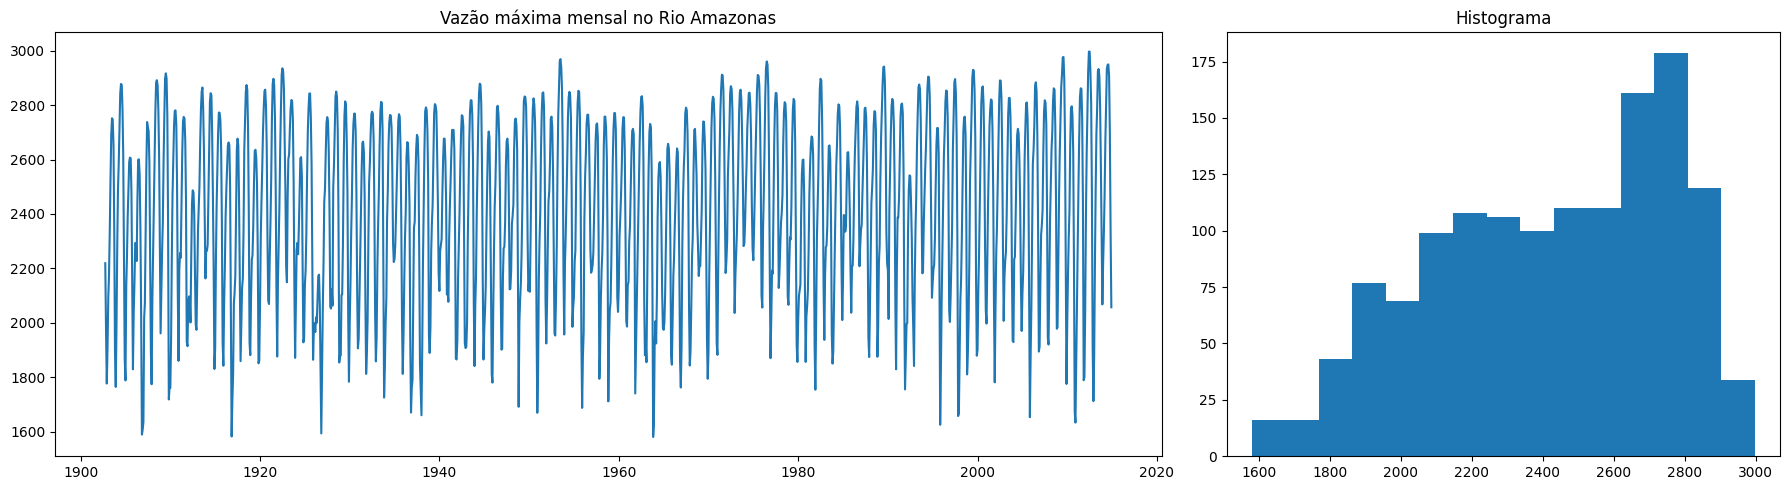

In [96]:
fig, ax = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={'width_ratios': [2, 1]})

ax[0].plot(series)
ax[0].set_title('Vazão máxima mensal no Rio Amazonas')

ax[1].hist(series, bins=15)
ax[1].set_title('Histograma')

plt.tight_layout()
plt.show()

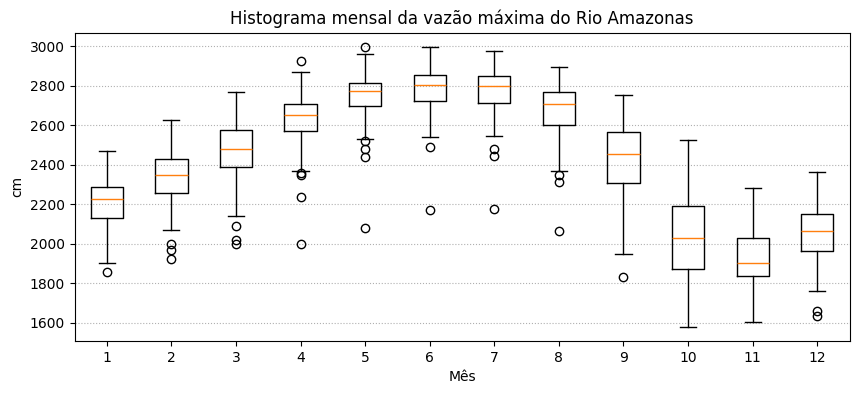

In [5]:
fig, ax = plt.subplots(figsize=(10,4))
plot_data = (series
    .pivot_table(columns=series.index.month, index=series.index.year, values='Maxima')
    .dropna()
)
ax.boxplot(plot_data)
ax.set_ylabel('cm')
ax.set_xlabel('Mês')
ax.grid(axis='y', linestyle=':')
ax.set_title('Histograma mensal da vazão máxima do Rio Amazonas')
plt.show()

## Modelagem

\begin{align}
y_t &= \mu_{t|t-1} + \gamma_t+\varphi\varepsilon_t, \qquad \text{com} \quad
\varepsilon_t \sim
\operatorname{GEV}(0,1,\xi_t) \quad \text{e} \quad
\varphi > 0 \\
\mu_{t+1|t} &= \mu(1-\phi) +\phi\mu_{t|t-1} +\kappa s_t \\
\gamma_t &=
\sum_{j=1}^{6}
\left(
\alpha_j
\cos\left(\frac{2\pi jt}{12}\right)
+
\beta_j
\sin\left(\frac{2\pi jt}{12}\right)
\right)
\end{align}

In [60]:
importlib.reload(harvey)

<module 'harvey_gev' from 'C:\\Users\\aless\\Desktop\\Codes\\masters\\Tese\\harvey_gev.py'>

In [80]:
y = series['Maxima']
mu_init, alpha_init, beta_init = harvey.initial_seasonal_coefficients(y)

t = np.arange(1, len(series) + 1)
gamma_init = harvey.seasonal_component(t, alpha_init, beta_init)
residuos_init = y.to_numpy(dtype=float) - mu_init - gamma_init
varphi_init = np.std(residuos_init)

print(f"mu inicial: {mu_init:.2f}")
print(f"varphi inicial: {varphi_init:.2f}")

# temporada de cheia de março a agosto
dummy = series.index.month.isin([3,4,5,6,7,8]).astype(int)

mu inicial: 2422.10
varphi inicial: 147.10


In [81]:
bounds = [
    (None, None),   # mu0
    (1e-8, None),   # varphi > 0
    (-0.999, 0.999),   # -1 < phi < 1
    (1e-8, None),   # kappa > 0
    (1e-8, 1),     # 0 < xi_seca < 1/2
    # (1e-8, 1)     # 0 < xi_cheia < 1/2
]
bounds += [(None, None)] * 11  # alpha e beta

init_params = [
    2422,     # mu
    147,     # varphi
    0.55,   # phi
    0.3,    # kappa
    0.1,    # xi seca
    # 0.2, # xi cheia
    *alpha_init,
    *beta_init
]
start = dt.datetime.now()
print(start)
result = harvey.fit(y, dummy, init_params, bounds=None, xi_mode="constant")
end = dt.datetime.now()
print(f"Tempo de execução: {(end-start).seconds//60:02d}:{(end-start).seconds%60:02d}")

mu_hat, varphi_hat, phi_hat, kappa_hat, xi_seca_hat, xi_cheia_hat = result.params_original[:6]
alpha_hat = result.params_original[6:12]
beta_hat = result.params_original[12:17]

2026-10-20 09:47:16.289254
Tempo de execução: 02:52


In [83]:
print("Convergiu:", result.success)
print("Mensagem:", result.message)

print("\nEstimativas:")
print(f"mu: {result.params_original[0]:.3f}")
print(f"varphi: {result.params_original[1]:.3f}")
print(f"phi: {result.params_original[2]}")
print(f"kappa: {result.params_original[3]}")
print(f"xi seca: {result.params_original[4]}")
print(f"xi cheia: {result.params_original[5]}")

print("\nLog-likelihood =", -result.fun)

Convergiu: True
Mensagem: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH

Estimativas:
mu: 2035.073
varphi: 104.508
phi: 0.6613157550347734
kappa: 2.8937243443352294
xi seca: 1e-08
xi cheia: 1e-08

Log-likelihood = -8218.161885560336


In [82]:
result

         message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
         success: True
          status: 0
             fun: 8218.161885560336
               x: [ 2.035e+03  1.045e+02 ...  7.985e+00  4.237e+00]
             nit: 75
             jac: [ 5.695e-01  1.572e+00 ... -1.161e-01  2.043e+00]
            nfev: 1938
            njev: 114
        hess_inv: <16x16 LbfgsInvHessProduct with dtype=float64>
 params_original: [ 2.035e+03  1.045e+02 ...  7.985e+00  4.237e+00]

## Avaliação

In [ ]:
mu_filtered, gamma_t, x, s, xi_t = harvey.filter(
    y, mu_hat, varphi_hat, phi_hat, kappa_hat, xi_seca_hat, xi_cheia_hat, dummy, alpha_hat, beta_hat
)
eta_t = mu_filtered + gamma_t
mean_cond = harvey.conditional_mean(mu_filtered, varphi_hat, xi_t, gamma_t)

pit = harvey.cdf(y, mu_filtered, varphi_hat, xi_t, gamma_t)

In [102]:
# regiões modificadas do score
mask_gumbel = (np.abs(xi_t) < 1e-6) & (x < 0)
mask_lower = np.zeros(len(x), dtype=bool)
mask_upper = np.zeros(len(x), dtype=bool)

c, d = {}, {}
c_t = np.full(len(x), np.nan)
d_t = np.full(len(x), np.nan)

for xi_value in np.unique(xi_t):
    if xi_value > 1e-6:
        c[xi_value] = harvey._find_c(xi_value)
        d[xi_value] = harvey._find_d(xi_value)

for i in range(len(x)):
    if xi_t[i] > 1e-6:
        c_t[i], d_t[i] = c[xi_value], d[xi_value]
        mask_lower[i] = x[i] <= c_t[i]
        mask_upper[i] = x[i] > d_t[i]

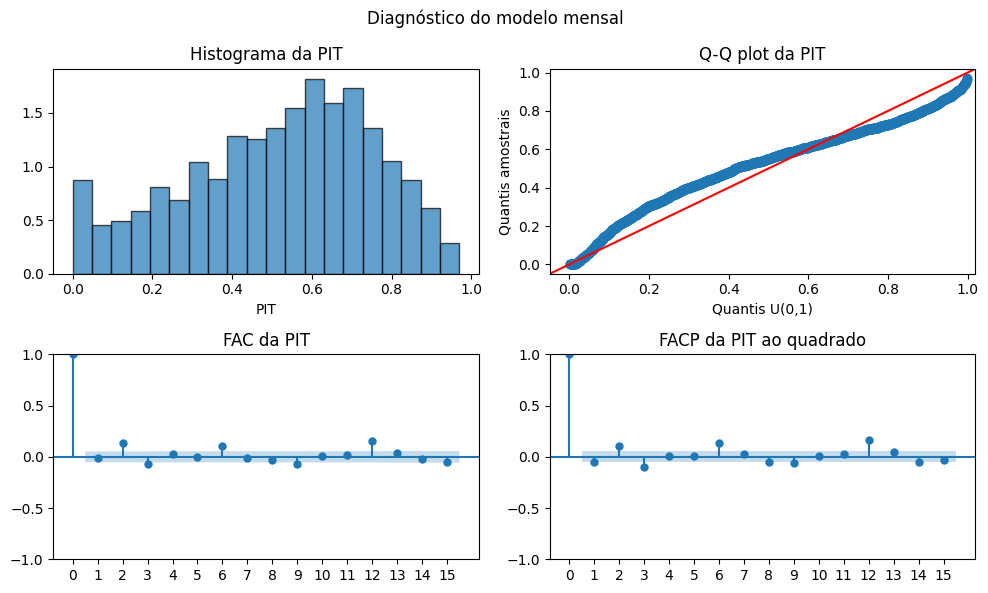

In [85]:
# pit
fig, ax = plt.subplots(2, 2, figsize=(10, 6))

# linha 1
ax[0,0].hist(pit, bins=20, density=True, edgecolor='black', alpha=0.7)
ax[0,0].set_title('Histograma da PIT')
ax[0,0].set_xlabel('PIT')

ax[0,1].set_title('Q-Q plot da PIT')
sm.qqplot(pit, dist=uniform, line='45', ax=ax[0,1], loc=0, scale=1)
ax[0,1].set_xlabel('Quantis U(0,1)')
ax[0,1].set_ylabel('Quantis amostrais')

# linha 2
lags = 15

plot_acf(pit, lags=lags, ax=ax[1,0], title='FAC da PIT')
ax[1,0].set_xticks(np.arange(lags+1))
ax[1,0].set_xticklabels(np.arange(lags+1))

plot_pacf(pit**2, lags=lags, ax=ax[1,1], title='FACP da PIT ao quadrado')
ax[1,1].set_xticks(np.arange(lags+1))
ax[1,1].set_xticklabels(np.arange(lags+1))

fig.suptitle('Diagnóstico do modelo mensal')
fig.tight_layout()
plt.show()

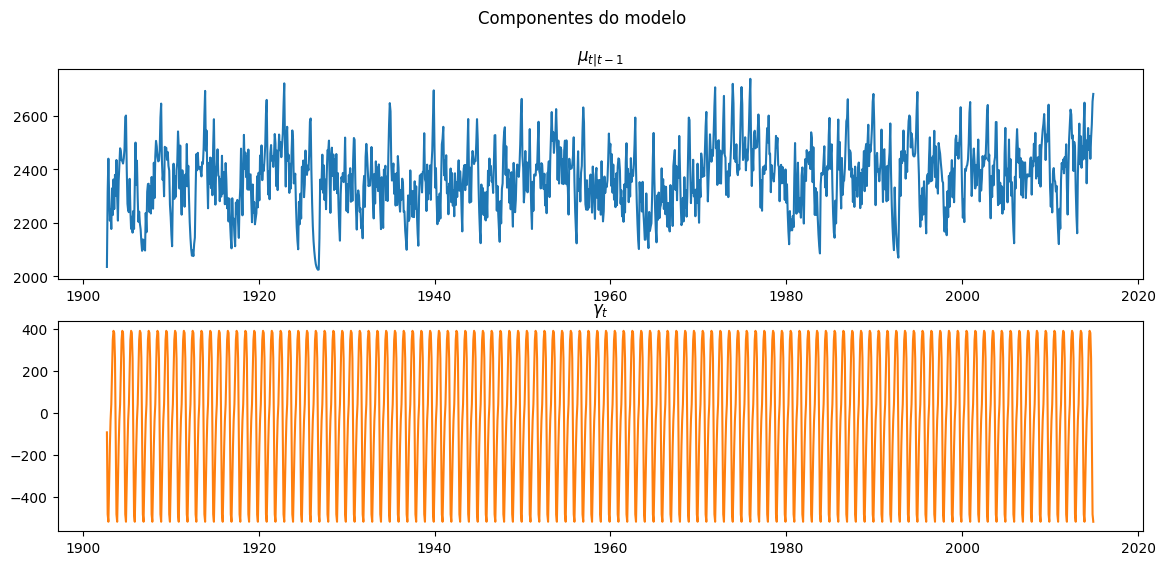

In [86]:
fig, ax = plt.subplots(2, 1, figsize=(14, 6))

ax[0].plot(series.index, mu_filtered, label=r"$\mu_{t|t-1}$")
ax[0].set_title(r"$\mu_{t|t-1}$")

ax[1].plot(series.index, gamma_t, label=r"$\gamma_t$", color='C1')
ax[1].set_title(r"$\gamma_t$")

fig.suptitle("Componentes do modelo")
# plt.legend()
plt.show()

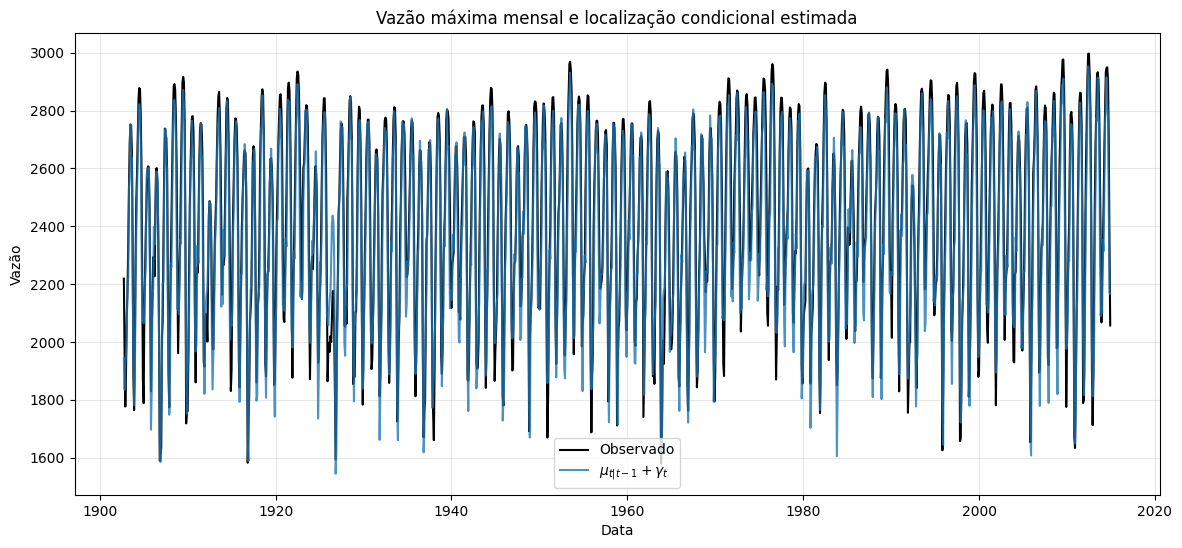

In [91]:
plt.figure(figsize=(14, 6))

plt.plot(series.index, series, label="Observado", color='black')
plt.plot(series.index, eta_t, label=r"$\mu_{t|t-1} + \gamma_t$", alpha=0.8)
# plt.plot(series.index, mean_cond, label=r"$E[y_t|\mathcal{F}_{t-1}]$")

plt.xlabel("Data")
plt.ylabel("Vazão")
plt.title("Vazão máxima mensal e localização condicional estimada")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

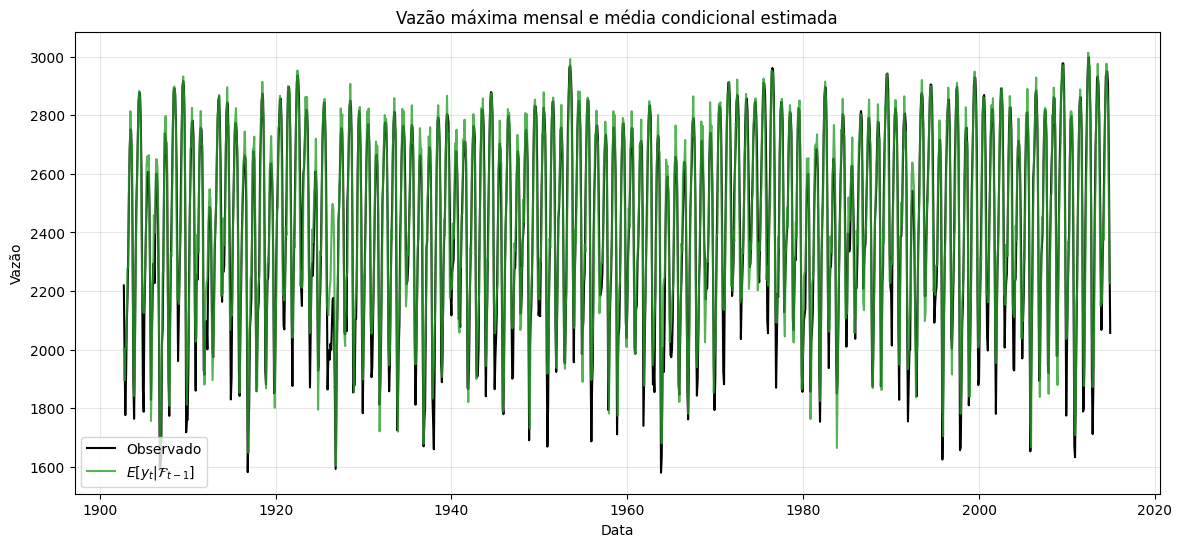

In [94]:
plt.figure(figsize=(14, 6))

plt.plot(series.index, series, label="Observado", color='black')
# plt.plot(series.index, eta_t, label=r"$\mu_{t|t-1} + \gamma_t$")
plt.plot(series.index, mean_cond, label=r"$E[y_t|\mathcal{F}_{t-1}]$", color='C2', alpha=0.8)

plt.xlabel("Data")
plt.ylabel("Vazão")
plt.title("Vazão máxima mensal e média condicional estimada")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [126]:
series.loc[:'1960'].index[mask_gumbel[:idx]].shape[0]

195

In [128]:
len(s[mask_gumbel][:idx])

359

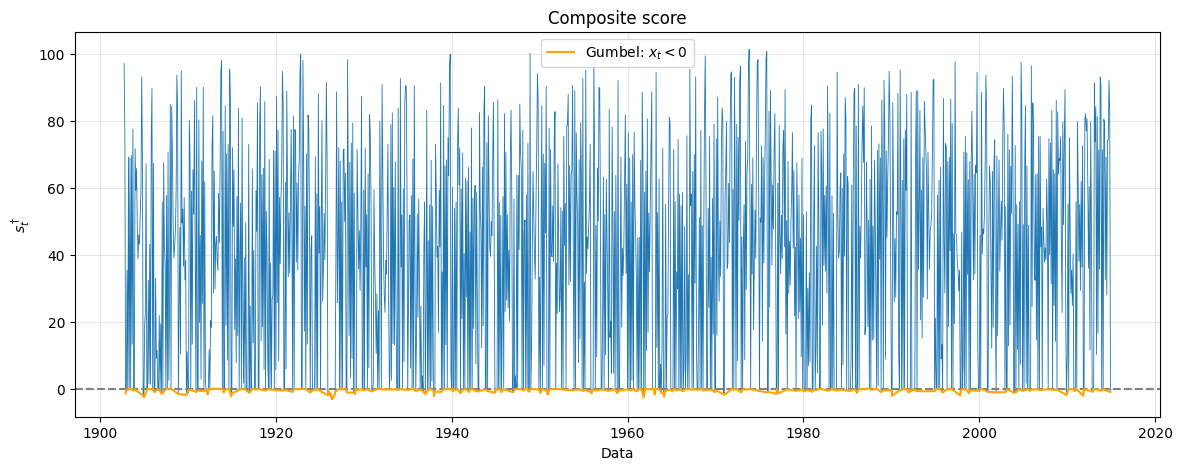

In [134]:
plt.figure(figsize=(14, 5))

plt.plot(series.index, s, linewidth=0.6)

plt.plot(series.index[mask_gumbel], s[mask_gumbel], color="orange", zorder=3, label=r"Gumbel: $x_t<0$")
# plt.scatter(series.index[mask_lower], s[mask_lower], color="red", s=28, zorder=3, label=r"$\xi_t>0$: $x_t\leq c_t$")
# plt.scatter(series.index[mask_upper], s[mask_upper], color="purple", s=28, zorder=3, label=r"$\xi_t>0$: $x_t>d_t$")

plt.axhline(0, linestyle="--", color='gray')

plt.xlabel("Data")
plt.ylabel(r"$s_t^\dagger$")
plt.title("Composite score")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

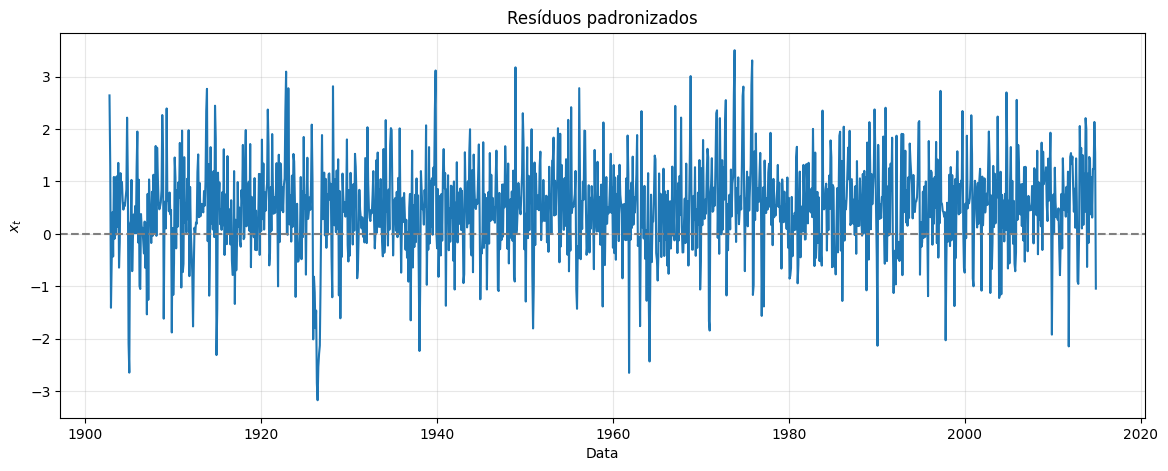

In [96]:
plt.figure(figsize=(14, 5))

plt.plot(series.index, x)
plt.axhline(0, linestyle="--", color='gray')

plt.xlabel("Data")
plt.ylabel(r"$x_t$")
plt.title("Resíduos padronizados")
plt.grid(alpha=0.3)

plt.show()

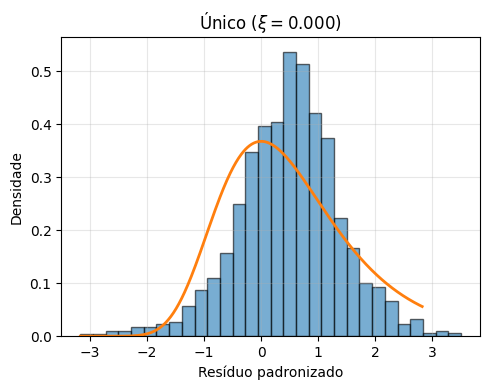

In [101]:
fig, ax = plt.subplots(figsize=(5, 4))

# Grade da densidade teórica
x_grid = np.linspace(np.min(x), np.percentile(x, 99.5), 500)

# Histograma dos resíduos padronizados
ax.hist(x, bins=30, density=True, alpha=0.6, edgecolor="black")
pdf = genextreme.pdf(x_grid, c=-xi_seca_hat, loc=0, scale=1)
ax.plot(x_grid, pdf, linewidth=2) # Densidade teórica

ax.set_title(f"Único ($\\xi={xi_seca_hat:.3f}$)")
ax.set_xlabel("Resíduo padronizado")
ax.set_ylabel("Densidade")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

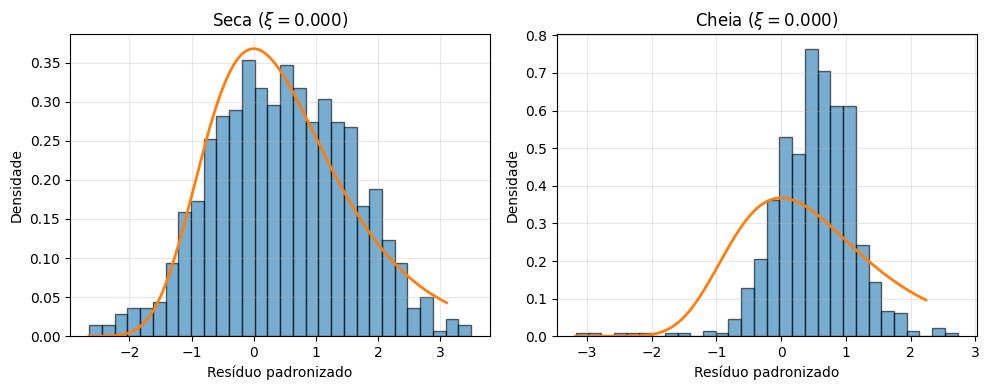

In [97]:
# Separar os resíduos por regime
regimes = [
    (x[dummy == 0], xi_seca_hat, "Seca"),
    (x[dummy == 1], xi_cheia_hat, "Cheia")
]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (x_regime, xi_hat, nome) in zip(axes, regimes):
    # Grade da densidade teórica
    x_grid = np.linspace(np.min(x_regime), np.percentile(x_regime, 99.5), 500)

    # Histograma dos resíduos padronizados
    ax.hist(x_regime, bins=30, density=True, alpha=0.6, edgecolor="black")
    pdf = genextreme.pdf(x_grid, c=-xi_hat, loc=0, scale=1)
    ax.plot(x_grid, pdf, linewidth=2) # Densidade teórica

    ax.set_title(f"{nome} ($\\xi={xi_hat:.3f}$)")
    ax.set_xlabel("Resíduo padronizado")
    ax.set_ylabel("Densidade")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

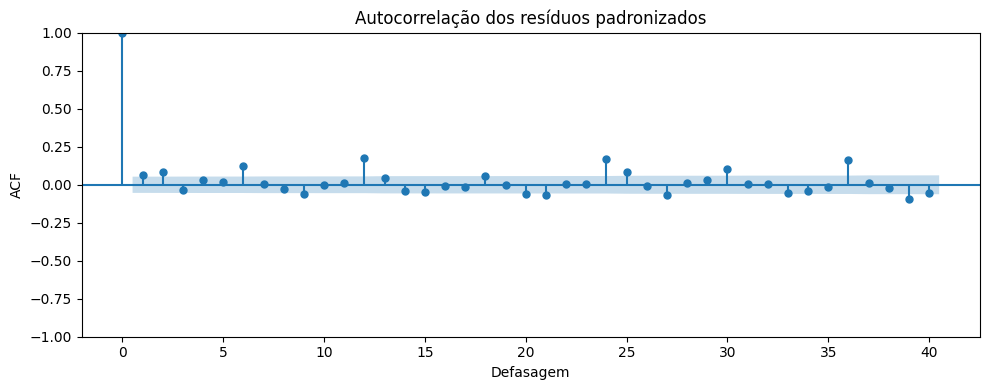

In [98]:
plt.figure(figsize=(10, 4))
plot_acf(x, lags=40, ax=plt.gca())
plt.title("Autocorrelação dos resíduos padronizados")
plt.xlabel("Defasagem")
plt.ylabel("ACF")
plt.tight_layout()
plt.show()

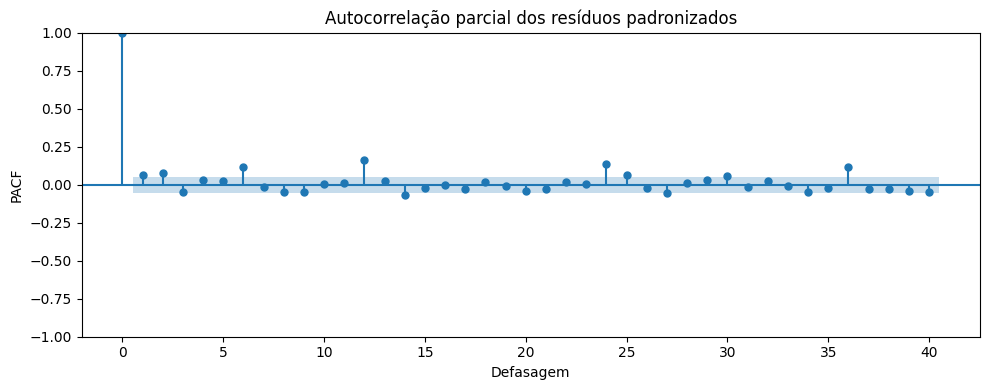

In [99]:
plt.figure(figsize=(10, 4))
plot_pacf(x, lags=40, ax=plt.gca())
plt.title("Autocorrelação parcial dos resíduos padronizados")
plt.xlabel("Defasagem")
plt.ylabel("PACF")
plt.tight_layout()
plt.show()

# Dados Harvey

- Dados Harvey: daily river Exe flow e level na base de Thorverton [https://environment.data.gov.uk/hydrology/station/3c4d4f78-2d0e-474a-b884-65a9daca18fb]  
  Grid Reference: SS9360201602
  River Name: River Exe  
  Catchment Area: 600.9 km²  
  Station Reference (Telemetry): 45118  
  Station ID (WISKI): SS90F011  
  API: https://environment.data.gov.uk/hydrology/doc/reference

In [135]:
path = r"C:\Users\aless\Documents\Mestrado\PUC\Tese\Dados\Thorverton-flow-daily-Qualified.csv"

data = pd.read_csv(path)

data['date'] = pd.to_datetime(data['date'])

data = data.set_index('date').dropna(how='all')
series = data[['value']].resample('ME').max()

print(series.shape)
series.head(3)

(847, 1)


,value
date,
1956-04-30,4.283
1956-05-31,4.214
1956-06-30,11.329


In [31]:
# metadados
pd.set_option('display.max_colwidth', None)
pd.DataFrame(index=['Metadados'], data={
    'Fonte':'''Base de dados de vazão do Rio Amazonas da Agência Nacional de Águas (ANA)''', 
    'Unidade':'centímetros (cm)',
    'Período da série': '{} a {}'.format(series.index.min().strftime('%d/%m/%Y'), series.index.max().strftime('%d/%m/%Y')),
    'Observações': '{} meses'.format(series.shape[0])
}).T

,Metadados
Fonte,Base de dados de vazão do Rio Amazonas da Agência Nacional de Águas (ANA)
Unidade,centímetros (cm)
Período da série,30/04/1956 a 31/10/2026
Observações,847 meses


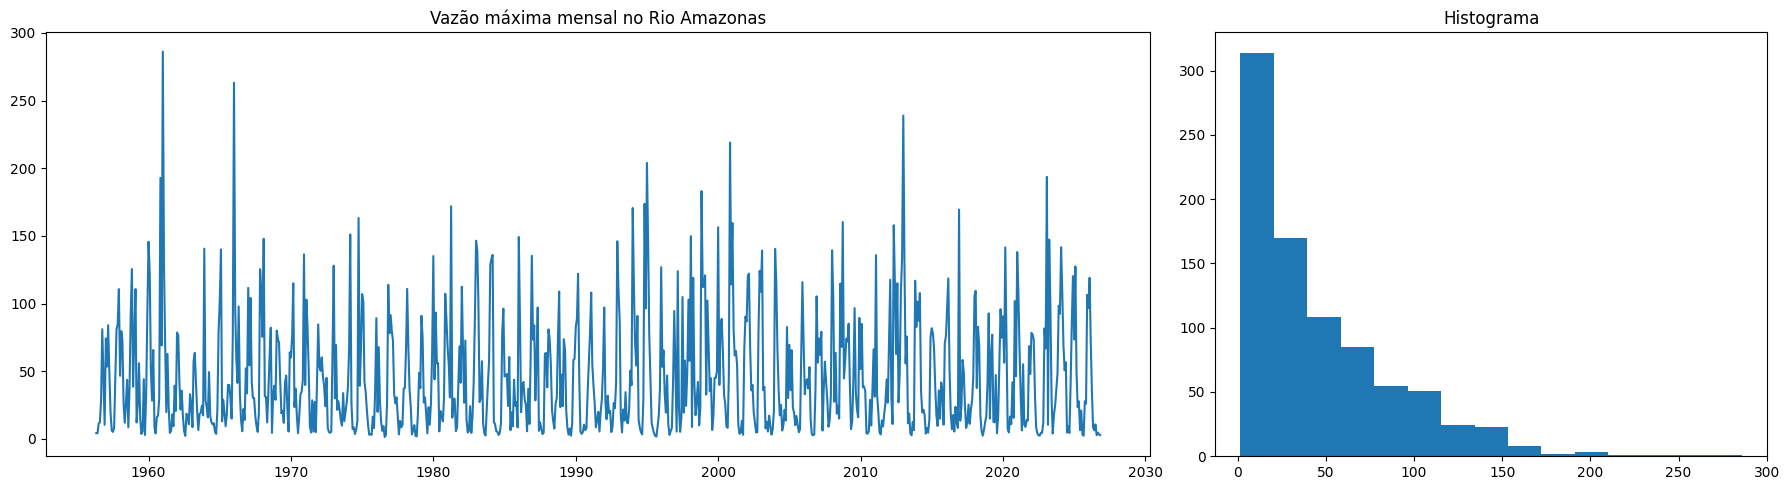

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={'width_ratios': [2, 1]})

ax[0].plot(series)
ax[0].set_title('Vazão máxima mensal no Rio Amazonas')

ax[1].hist(series, bins=15)
ax[1].set_title('Histograma')

plt.tight_layout()
plt.show()

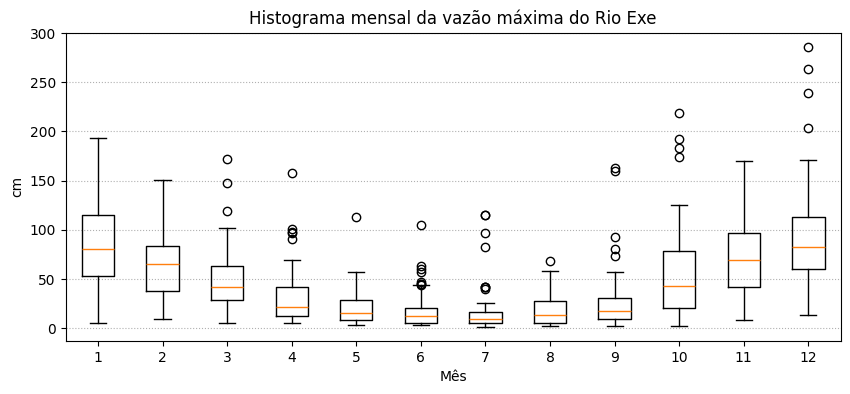

In [38]:
fig, ax = plt.subplots(figsize=(10,4))
plot_data = (series
    .pivot_table(columns=series.index.month, index=series.index.year, values='value')
    .dropna()
)
ax.boxplot(plot_data)
ax.set_ylabel('cm')
ax.set_xlabel('Mês')
ax.grid(axis='y', linestyle=':')
ax.set_title('Histograma mensal da vazão máxima do Rio Exe')
plt.show()

## Modelagem

In [136]:
y = series['value']
mu_init, alpha_init, beta_init = harvey.initial_seasonal_coefficients(y)

t = np.arange(1, len(y) + 1)
gamma_init = harvey.seasonal_component(t, alpha_init, beta_init)
residuos_init = y.to_numpy(dtype=float) - mu_init - gamma_init
varphi_init = np.std(residuos_init)

print(f"mu inicial: {mu_init:.2f}")
print(f"varphi inicial: {varphi_init:.2f}")

mu inicial: 45.89
varphi inicial: 32.93


In [141]:
# temporada de cheia (verão) de abril a setembro
dummy = series.index.month.isin([4,5,6,7,8,9]).astype(int)
bounds = [
    (None, None),   # mu0
    (1e-8, None),   # varphi > 0
    (-0.999, 0.999),  # -1 < phi < 1
    (1e-8, None),  # kappa > 0
    (1e-8, 0.999),     # 0 < xi_seca < 1/2
    (1e-8, 0.999)     # 0 < xi_cheia < 1/2
]
bounds += [(None, None)] * 11  # alpha e beta

init_params = [
    46,     # mu
    33,     # varphi
    0.55,   # phi
    0.3,    # kappa
    0.1,    # xi seca
    0.3, # xi cheia
    *alpha_init,
    *beta_init
]
start = dt.datetime.now()
print(start)
result = harvey.fit(y, dummy, init_params, bounds=bounds, xi_mode="seasonal")
end = dt.datetime.now()
print(f"Tempo de execução: {(end-start).seconds//60:02d}:{(end-start).seconds%60:02d}")

mu_hat, varphi_hat, phi_hat, kappa_hat, xi_seca_hat, xi_cheia_hat = result.params_original[:6]
alpha_hat = result.params_original[6:12]
beta_hat = result.params_original[12:17]

2026-10-20 18:54:55.866847
Tempo de execução: 00:33


In [142]:
print("Convergiu:", result.success)
print("Mensagem:", result.message)

print("\nEstimativas:")
print(f"mu: {result.params_original[0]:.3f}")
print(f"varphi: {result.params_original[1]:.3f}")
print(f"phi: {result.params_original[2]}")
print(f"kappa: {result.params_original[3]}")
print(f"xi seca: {result.params_original[4]}")
print(f"xi cheia: {result.params_original[5]}")

print("\nLog-likelihood =", -result.fun)

Convergiu: True
Mensagem: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH

Estimativas:
mu: 43.299
varphi: 33.217
phi: 0.21494470542823219
kappa: 0.1951056589978991
xi seca: 1e-08
xi cheia: 0.999

Log-likelihood = -4083.6999457356164


In [138]:
print("Convergiu:", result.success)
print("Mensagem:", result.message)

print("\nEstimativas:")
print(f"mu: {result.params_original[0]:.3f}")
print(f"varphi: {result.params_original[1]:.3f}")
print(f"phi: {result.params_original[2]}")
print(f"kappa: {result.params_original[3]}")
print(f"xi seca: {result.params_original[4]}")
print(f"xi cheia: {result.params_original[5]}")

print("\nLog-likelihood =", -result.fun)

Convergiu: True
Mensagem: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH

Estimativas:
mu: 43.296
varphi: 33.210
phi: 0.21553497014929668
kappa: 0.19582316206554062
xi seca: 1e-08
xi cheia: 1.0

Log-likelihood = -4083.436682761568


In [143]:
result

         message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
         success: True
          status: 0
             fun: 4083.6999457356164
               x: [ 4.330e+01  3.322e+01 ...  7.630e-01 -1.132e+00]
             nit: 9
             jac: [ 3.269e+00  3.975e+00 ...  3.248e+00  7.210e-01]
            nfev: 216
            njev: 12
        hess_inv: <17x17 LbfgsInvHessProduct with dtype=float64>
 params_original: [ 4.330e+01  3.322e+01 ...  7.630e-01 -1.132e+00]

In [87]:
xi_seca_harvey = 0.6
xi_cheia_harvey = 0
phi_seca_harvey = 8.24
phi_cheia_harvey = 32.13

In [88]:
for xi, phi in [(xi_cheia_harvey, phi_cheia_harvey), (xi_seca_harvey, phi_seca_harvey)]:
    if xi!=0:
        delta = (
            gamma_func(1-xi) - 1
        ) * phi / xi
    else:
        delta = 0.577*phi
    print(delta)

18.53901
16.729391067605587


## Avaliação

In [144]:
mu_filtered, gamma_t, x, s, xi_t = harvey.filter(
    y, mu_hat, varphi_hat, phi_hat, kappa_hat, xi_seca_hat, xi_cheia_hat, dummy, alpha_hat, beta_hat
)
eta_t = mu_filtered + gamma_t
mean_cond = harvey.conditional_mean(mu_filtered, varphi_hat, xi_t, gamma_t)

pit = harvey.cdf(y, mu_filtered, varphi_hat, xi_t, gamma_t)

In [145]:
# regiões modificadas do score
mask_gumbel = (np.abs(xi_t) < 1e-6) & (x < 0)
mask_lower = np.zeros(len(x), dtype=bool)
mask_upper = np.zeros(len(x), dtype=bool)

c, d = {}, {}
c_t = np.full(len(x), np.nan)
d_t = np.full(len(x), np.nan)

for xi_value in np.unique(xi_t):
    if xi_value > 1e-6:
        c[xi_value] = harvey._find_c(xi_value)
        d[xi_value] = harvey._find_d(xi_value)

for i in range(len(x)):
    if xi_t[i] > 1e-6:
        c_t[i], d_t[i] = c[xi_value], d[xi_value]
        mask_lower[i] = x[i] <= c_t[i]
        mask_upper[i] = x[i] > d_t[i]

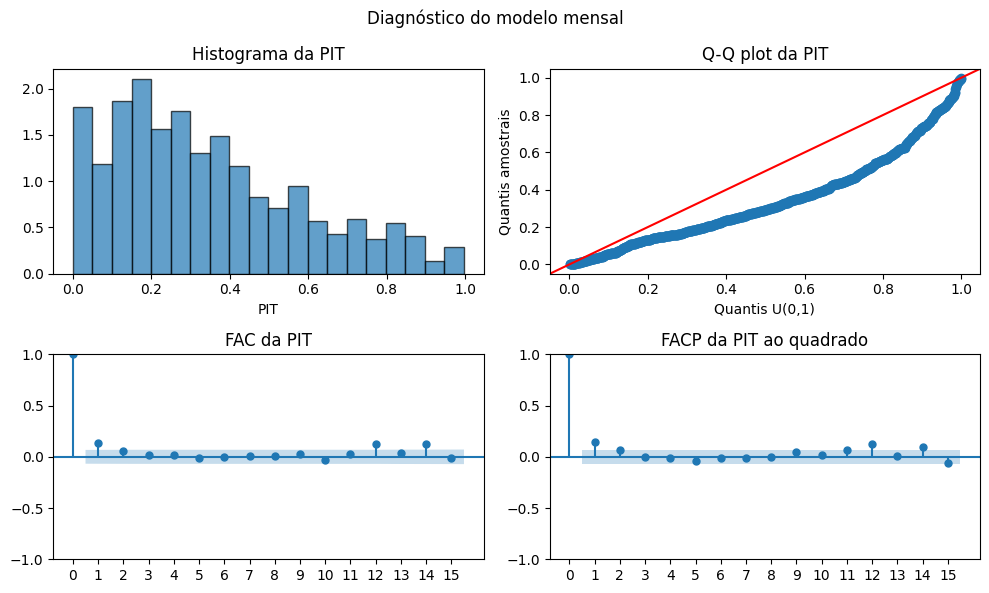

In [146]:
# pit
fig, ax = plt.subplots(2, 2, figsize=(10, 6))

# linha 1
ax[0,0].hist(pit, bins=20, density=True, edgecolor='black', alpha=0.7)
ax[0,0].set_title('Histograma da PIT')
ax[0,0].set_xlabel('PIT')

ax[0,1].set_title('Q-Q plot da PIT')
sm.qqplot(pit, dist=uniform, line='45', ax=ax[0,1], loc=0, scale=1)
ax[0,1].set_xlabel('Quantis U(0,1)')
ax[0,1].set_ylabel('Quantis amostrais')

# linha 2
lags = 15

plot_acf(pit, lags=lags, ax=ax[1,0], title='FAC da PIT')
ax[1,0].set_xticks(np.arange(lags+1))
ax[1,0].set_xticklabels(np.arange(lags+1))

plot_pacf(pit**2, lags=lags, ax=ax[1,1], title='FACP da PIT ao quadrado')
ax[1,1].set_xticks(np.arange(lags+1))
ax[1,1].set_xticklabels(np.arange(lags+1))

fig.suptitle('Diagnóstico do modelo mensal')
fig.tight_layout()
plt.show()

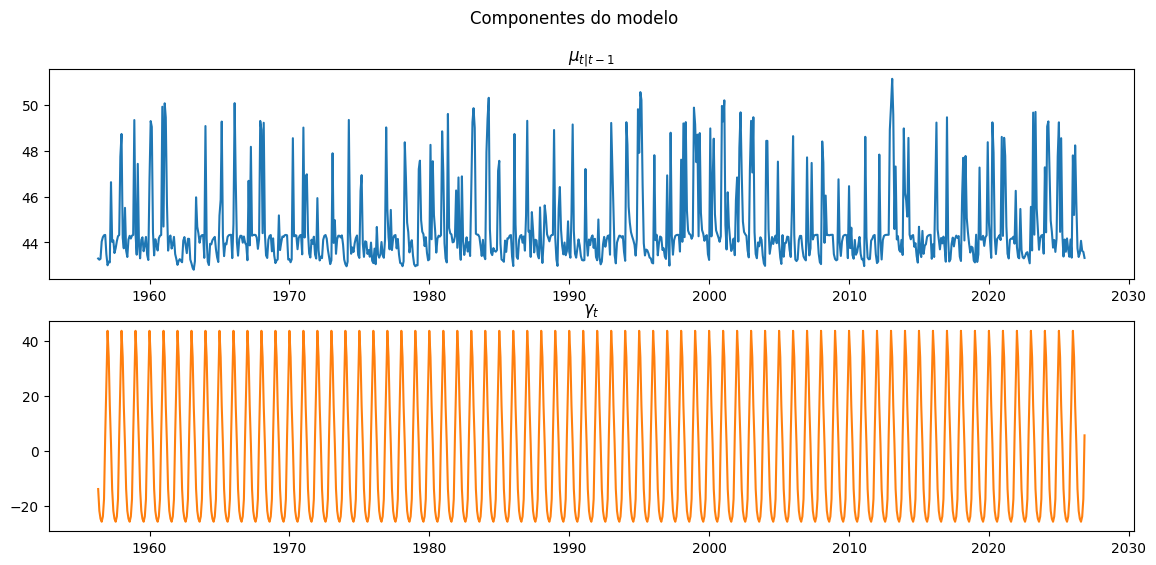

In [147]:
fig, ax = plt.subplots(2, 1, figsize=(14, 6))

ax[0].plot(series.index, mu_filtered, label=r"$\mu_{t|t-1}$")
ax[0].set_title(r"$\mu_{t|t-1}$")

ax[1].plot(series.index, gamma_t, label=r"$\gamma_t$", color='C1')
ax[1].set_title(r"$\gamma_t$")

fig.suptitle("Componentes do modelo")
# plt.legend()
plt.show()

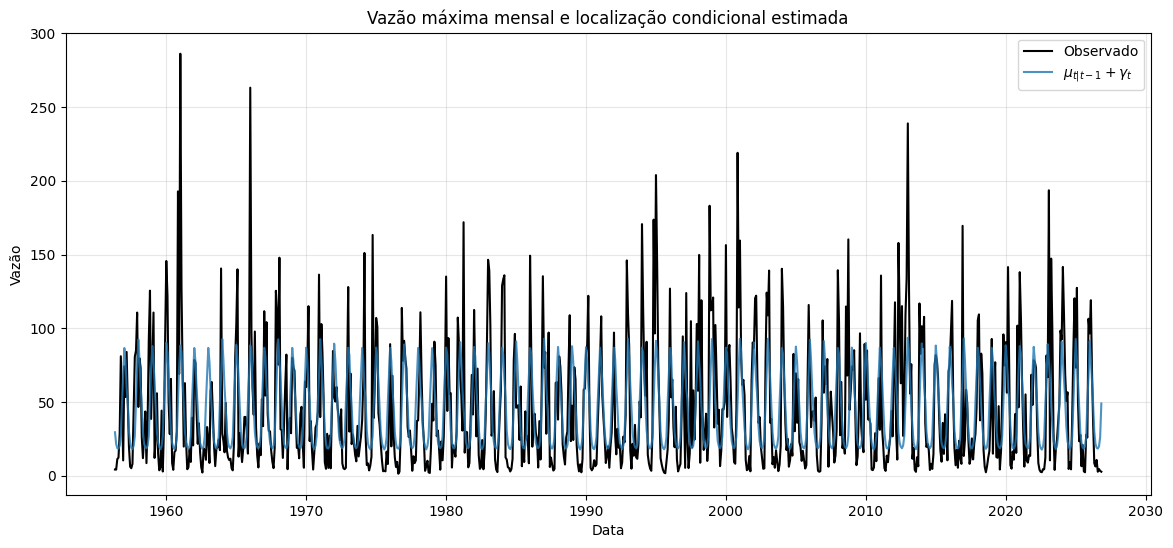

In [148]:
plt.figure(figsize=(14, 6))

plt.plot(series.index, series, label="Observado", color='black')
plt.plot(series.index, eta_t, label=r"$\mu_{t|t-1} + \gamma_t$", alpha=0.8)
# plt.plot(series.index, mean_cond, label=r"$E[y_t|\mathcal{F}_{t-1}]$")

plt.xlabel("Data")
plt.ylabel("Vazão")
plt.title("Vazão máxima mensal e localização condicional estimada")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

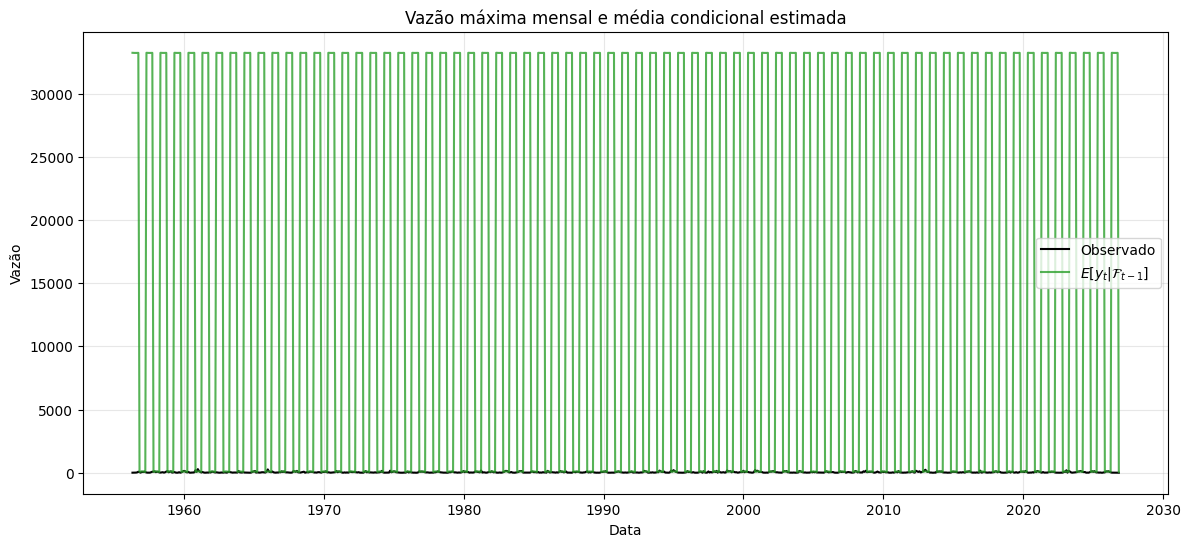

In [149]:
plt.figure(figsize=(14, 6))

plt.plot(series.index, series, label="Observado", color='black')
# plt.plot(series.index, eta_t, label=r"$\mu_{t|t-1} + \gamma_t$")
plt.plot(series.index, mean_cond, label=r"$E[y_t|\mathcal{F}_{t-1}]$", color='C2', alpha=0.8)

plt.xlabel("Data")
plt.ylabel("Vazão")
plt.title("Vazão máxima mensal e média condicional estimada")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(series.index, s, linewidth=0.6)

plt.plot(series.index[mask_gumbel], s[mask_gumbel], color="orange", zorder=3, label=r"Gumbel: $x_t<0$")
plt.plot(series.index[mask_lower], s[mask_lower], color="red", zorder=3, label=r"$\xi_t>0$: $x_t\leq c_t$")
# plt.scatter(series.index[mask_upper], s[mask_upper], color="purple", s=28, zorder=3, label=r"$\xi_t>0$: $x_t>d_t$")

plt.axhline(0, linestyle="--", color='gray')

plt.xlabel("Data")
plt.ylabel(r"$s_t^\dagger$")
plt.title("Composite score")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

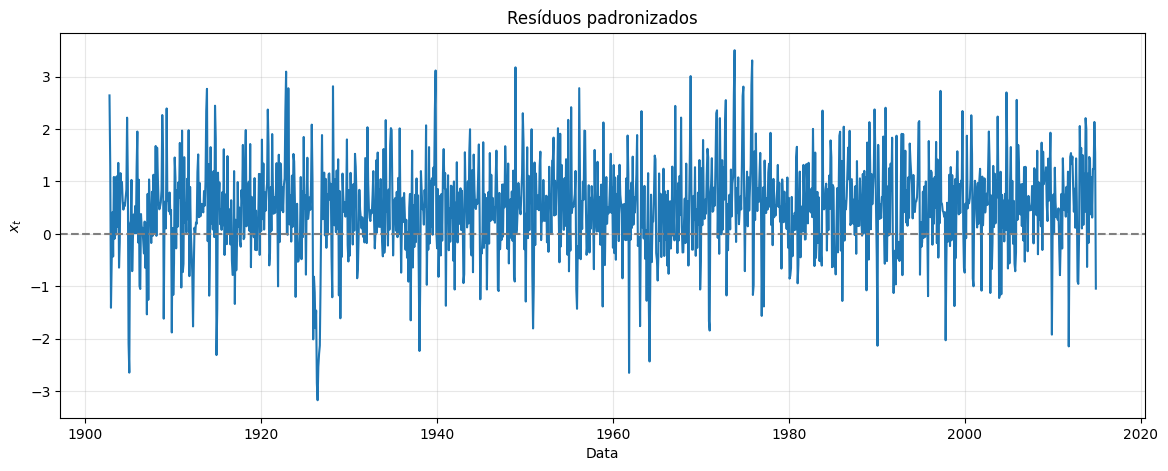

In [96]:
plt.figure(figsize=(14, 5))

plt.plot(series.index, x)
plt.axhline(0, linestyle="--", color='gray')

plt.xlabel("Data")
plt.ylabel(r"$x_t$")
plt.title("Resíduos padronizados")
plt.grid(alpha=0.3)

plt.show()

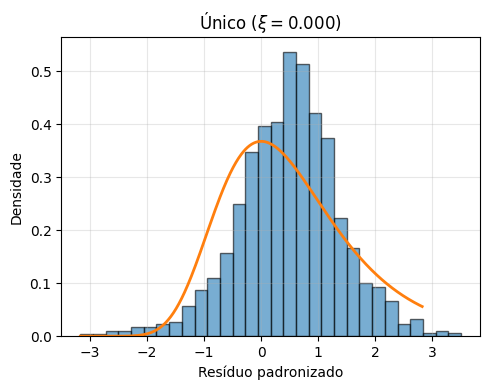

In [101]:
fig, ax = plt.subplots(figsize=(5, 4))

# Grade da densidade teórica
x_grid = np.linspace(np.min(x), np.percentile(x, 99.5), 500)

# Histograma dos resíduos padronizados
ax.hist(x, bins=30, density=True, alpha=0.6, edgecolor="black")
pdf = genextreme.pdf(x_grid, c=-xi_seca_hat, loc=0, scale=1)
ax.plot(x_grid, pdf, linewidth=2) # Densidade teórica

ax.set_title(f"Único ($\\xi={xi_seca_hat:.3f}$)")
ax.set_xlabel("Resíduo padronizado")
ax.set_ylabel("Densidade")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

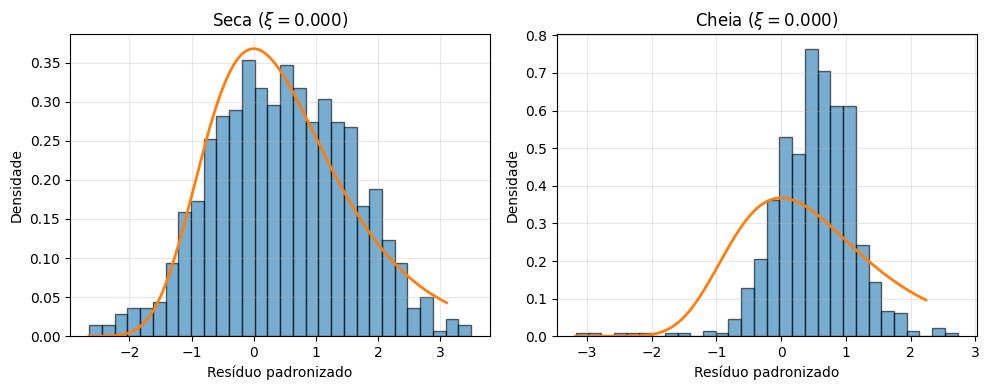

In [97]:
# Separar os resíduos por regime
regimes = [
    (x[dummy == 0], xi_seca_hat, "Seca"),
    (x[dummy == 1], xi_cheia_hat, "Cheia")
]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (x_regime, xi_hat, nome) in zip(axes, regimes):
    # Grade da densidade teórica
    x_grid = np.linspace(np.min(x_regime), np.percentile(x_regime, 99.5), 500)

    # Histograma dos resíduos padronizados
    ax.hist(x_regime, bins=30, density=True, alpha=0.6, edgecolor="black")
    pdf = genextreme.pdf(x_grid, c=-xi_hat, loc=0, scale=1)
    ax.plot(x_grid, pdf, linewidth=2) # Densidade teórica

    ax.set_title(f"{nome} ($\\xi={xi_hat:.3f}$)")
    ax.set_xlabel("Resíduo padronizado")
    ax.set_ylabel("Densidade")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

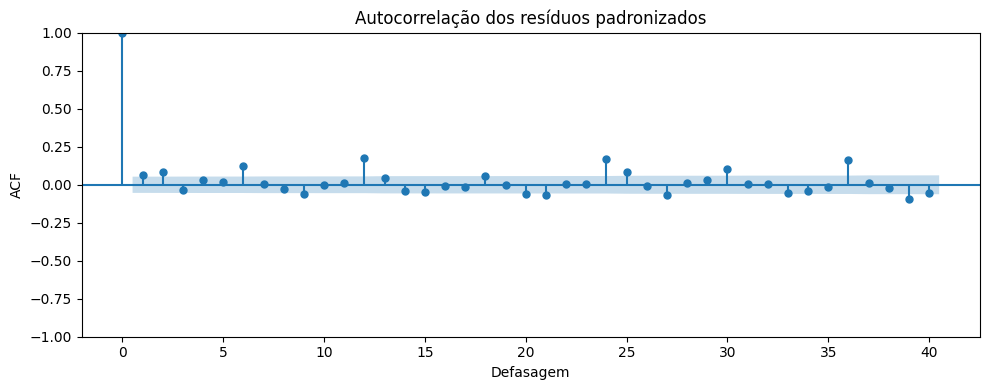

In [98]:
plt.figure(figsize=(10, 4))
plot_acf(x, lags=40, ax=plt.gca())
plt.title("Autocorrelação dos resíduos padronizados")
plt.xlabel("Defasagem")
plt.ylabel("ACF")
plt.tight_layout()
plt.show()

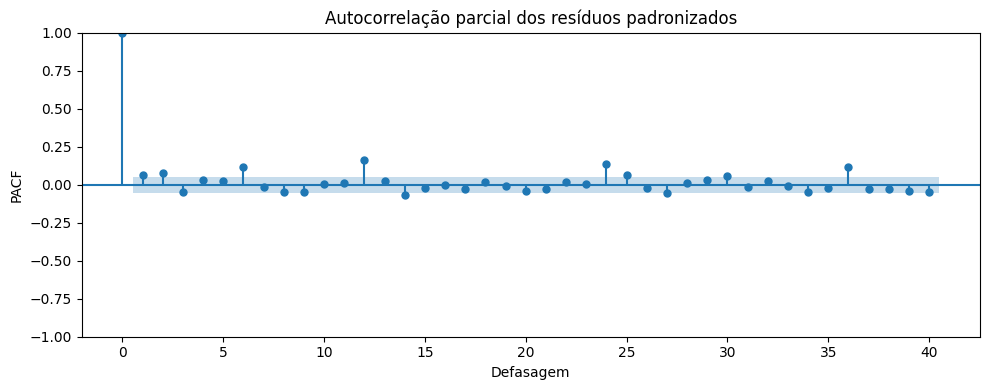

In [99]:
plt.figure(figsize=(10, 4))
plot_pacf(x, lags=40, ax=plt.gca())
plt.title("Autocorrelação parcial dos resíduos padronizados")
plt.xlabel("Defasagem")
plt.ylabel("PACF")
plt.tight_layout()
plt.show()